# CORUM sig-up pathway — TMB correlation bar chart

Output: `results/figures/supplementary/supp_fig1/corum_sig_up_pathway_tmb_corr.pdf`

Pearson r of each pathway score vs log10(TMB), with cancer-type bootstrap 95% CIs (same style as `fig1d_pathway_corr_bs_types.ipynb`).

In [1]:
import socket
import os
import sys

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser(
        "~/Documents/research/scg/protein-master/v2_pancan_batch_corrected"
    )

OUT_DIR = f"{BASE_DIR}/results/figures/supplementary/supp_fig1"
os.makedirs(OUT_DIR, exist_ok=True)

sys.path.insert(0, f"{BASE_DIR}/local/figures")
from palette import COLORS

In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.stats import pearsonr

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

In [3]:
corr_df = pd.read_csv(
    f"{BASE_DIR}/analysis/03_complex/corr_corum_sig_up_pathway_vs_tmb.csv"
)
corr_sorted = corr_df.sort_values("r", ascending=True)

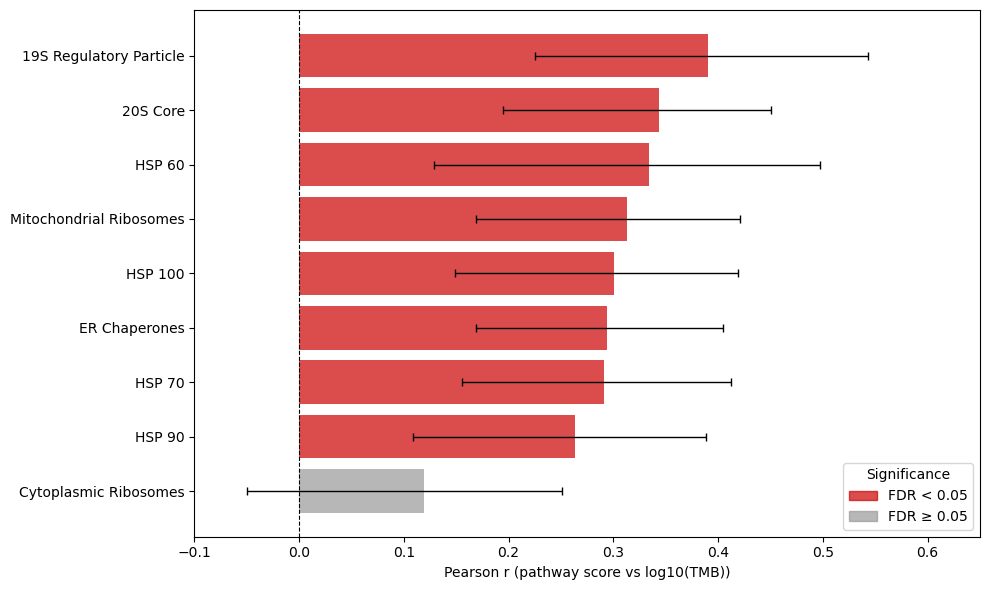

Saved → /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/results/figures/supplementary/supp_fig1/corum_sig_up_pathway_tmb_corr.pdf


In [4]:
# ── Bar plot (fig1d style) ───────────────────────────────────────────────────
FIG_SIZE = (10, 6)
COLOR_SIG = COLORS["sig_strong"]
COLOR_NS = COLORS["ns"]
ALPHA = 0.7
OUT_PATH = f"{OUT_DIR}/corum_sig_up_pathway_tmb_corr.pdf"

colors = [COLOR_SIG if p < 0.05 else COLOR_NS for p in corr_sorted["fdr"]]

fig, ax = plt.subplots(figsize=FIG_SIZE)
ax.barh(corr_sorted["complex"], corr_sorted["r"], color=colors, alpha=ALPHA)
ax.errorbar(
    x=corr_sorted["r"],
    y=corr_sorted["complex"],
    xerr=[
        corr_sorted["r"] - corr_sorted["ci_low"],
        corr_sorted["ci_high"] - corr_sorted["r"],
    ],
    fmt="none",
    color="black",
    capsize=3,
    linewidth=1,
)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlim(-0.1, 0.65)
ax.set_xlabel("Pearson r (pathway score vs log10(TMB))")

legend_handles = [
    mpatches.Patch(color=COLOR_SIG, alpha=ALPHA, label="FDR < 0.05"),
    mpatches.Patch(color=COLOR_NS, alpha=ALPHA, label="FDR ≥ 0.05"),
]
ax.legend(handles=legend_handles, title="Significance", loc="lower right")

plt.tight_layout()
plt.savefig(OUT_PATH, dpi=300)
plt.show()
print(f"Saved → {OUT_PATH}")